In [32]:
import sys
import os

In [33]:
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

In [34]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
        
from core.models import GetModel
import json

In [35]:
def GetModelFromConfig(path):
    config_path =  "config.json"
    with open(config_path, "r") as f:
        config = json.load(f)
                
    model = GetModel(config)
    
    return model, config["experiment"]["N"]

In [36]:
import plotly.graph_objects as go
from sklearn.decomposition import PCA
import numpy as np

def plot_input_only_plotly(model, N):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    offset = 2 * N * N 
    labels = np.arange(-N, N + 1)
    indices = labels + offset
    
    valid_indices = [i for i in indices if 0 <= i < weights.shape[0]]
    input_weights = weights[valid_indices]
    labels = labels[:len(valid_indices)]
    
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(input_weights)
    

    fig = go.Figure()
    
    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top center",
        marker=dict(
            size=14,
            color='red',
            line=dict(width=1, color='black')
        ),
        hoverinfo='text',
        hovertext=[f"Wartość wejściowa: {l}<br>Index w embed: {l + offset}" for l in labels]
    ))
    
    fig.update_layout(
        title=f"Struktura liczb wejściowych (Embeddings) dla N={N}",
        xaxis_title="PCA Component 1",
        yaxis_title="PCA Component 2",
        plot_bgcolor='white',
        width=700,
        height=700
    )
    
    fig.update_xaxes(showgrid=True, gridcolor='lightgray')
    fig.update_yaxes(showgrid=True, gridcolor='lightgray')
    
    fig.show()

In [37]:
model, N = GetModelFromConfig("")

model_path = r"checkpoint_epoch_7000.pt"

checkpoint = torch.load(model_path, map_location="cpu")

model_weights = checkpoint["model_state_dict"]
model.load_state_dict(model_weights)

plot_input_only_plotly(model, N=N)

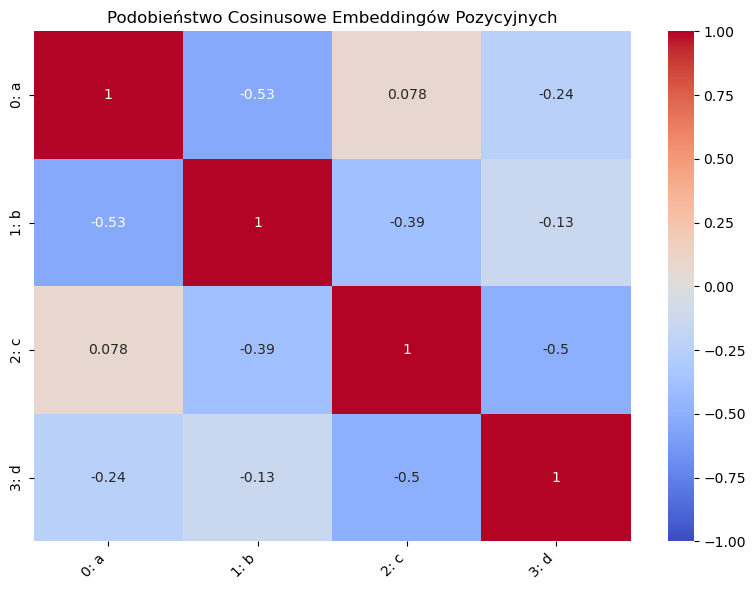

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_positional_embeddings(model):
    pos_weights = model.pos_embed.weight.detach().cpu().numpy()
    
    norm = np.linalg.norm(pos_weights, axis=1, keepdims=True)
    normalized_pos = pos_weights / norm
    
    cosine_sim = np.dot(normalized_pos, normalized_pos.T)
    
    plt.figure(figsize=(8, 6))
    

    labels = [
        '0: a', '1: b', '2: c', '3: d',
    ]
    
    sns.heatmap(
        cosine_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    
    plt.title("Podobieństwo Cosinusowe Embeddingów Pozycyjnych")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


analyze_positional_embeddings(model)

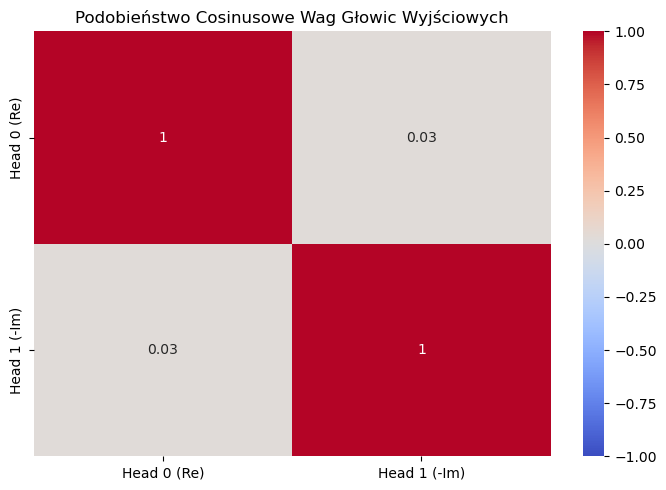

In [39]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_output_heads(model):
    heads_weights = [head.weight.detach().cpu().numpy() for head in model.output_heads]
    
    flat_heads = [w.flatten() for w in heads_weights]
    flat_heads = np.array(flat_heads) 

    norm = np.linalg.norm(flat_heads, axis=1, keepdims=True)
    normalized_heads = flat_heads / norm
    head_sim = np.dot(normalized_heads, normalized_heads.T)
    

    labels = ['Head 0 (Re)', 'Head 1 (-Im)']
    
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        head_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    plt.title("Podobieństwo Cosinusowe Wag Głowic Wyjściowych")
    plt.tight_layout()
    plt.show()

analyze_output_heads(model)

In [ ]:
import torch
import numpy as np
from sklearn.cross_decomposition import CCA

def evaluate_and_run_cca(model, dataloader, device):
    model.eval()
    
    all_hidden_states = []
    all_a = []
    all_b = []
    all_c = []
    all_d = []
    
    with torch.no_grad():
        for batch_x, raw_a, raw_b, raw_c, raw_d in dataloader:
            batch_x = batch_x.to(device)
            
            X_emb = model.tokens_embed(batch_x) 
            pos = torch.arange(batch_x.shape[1], device=device).unsqueeze(0)
            X_pos = model.pos_embed(pos)
            X = X_emb + X_pos
            
            for layer in model.layers:
                X = layer(X)
                
            out = X[:, -1, :]
            
            all_hidden_states.append(out.cpu().numpy())
            all_a.extend(raw_a.numpy())
            all_b.extend(raw_b.numpy())
            all_c.extend(raw_c.numpy())
            all_d.extend(raw_d.numpy())
            
    hidden_states_np = np.concatenate(all_hidden_states, axis=0)
    z1_real = np.array(all_a)
    z1_imag = np.array(all_b)
    z2_real = np.array(all_c)
    z2_imag = np.array(all_d)
    
    correlations, cca_model = perform_polar_cca(
        hidden_states_np, 
        z1_real, z1_imag, 
        z2_real, z2_imag
    )
    
    return correlations

def perform_polar_cca(hidden_states_np, z1_real, z1_imag, z2_real, z2_imag):
    z1 = z1_real + 1j * z1_imag
    z2 = z2_real + 1j * z2_imag
    z_out = z1 * z2
    
    r_out = np.abs(z_out)
    phi_out = np.angle(z_out)
    
    log_r = np.log(r_out + 1e-8)
    sin_phi = np.sin(phi_out)
    cos_phi = np.cos(phi_out)
    
    Y = np.column_stack((log_r, sin_phi, cos_phi))
    X = hidden_states_np
    
    cca = CCA(n_components=3)
    cca.fit(X, Y)
    
    X_c, Y_c = cca.transform(X, Y)
    
    correlations = []
    for i in range(3):
        corr = np.corrcoef(X_c[:, i], Y_c[:, i])[0, 1]
        correlations.append(corr)
        
    print(f"Korelacja CCA - Wymiar 1: {correlations[0]:.4f}")
    print(f"Korelacja CCA - Wymiar 2: {correlations[1]:.4f}")
    print(f"Korelacja CCA - Wymiar 3: {correlations[2]:.4f}")
    
    return correlations, cca

evaluate_and_run_cca(model, )

In [ ]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly(model, N, head_idx=0):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()


    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]


    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.3
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    

    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

In [41]:
plot_output_head_plotly(model, N=N, head_idx=0)

plot_output_head_plotly(model, N=N, head_idx=1)


In [42]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d(model, N, head_idx=0):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]


    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

In [43]:
plot_output_head_plotly_3d(model, N=N, head_idx=0)

plot_output_head_plotly_3d(model, N=N, head_idx=1)

In [44]:
import os
import torch
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def animate_weight_evolution(model, N, epochs_list, head_idx=0):
    """
    Tworzy interaktywną animację PCA 2D pokazującą ewolucję wag wyjściowych w czasie.
    epochs_list: lista liczb oznaczających epoki, np. [1000, 2000, 5000, 12000]
    Assumes checkpoint files are named like: 'checkpoint_epoch_{epoch}.pt'
    """
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    
    history_embeds = {}
    valid_labels = None
    
    all_weights_stacked = []
    
    print("Wczytywanie checkpointów i dopasowywanie przestrzeni PCA...")
    for epoch in epochs_list:
        checkpoint_path = f"checkpoint_epoch_{epoch}.pt"
        if not os.path.exists(checkpoint_path):
            print(f"Pominięto epokę {epoch}: brak pliku {checkpoint_path}")
            continue
            
        checkpoint = torch.load(checkpoint_path, map_location="cpu")

        state_dict = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
        

        weight_key = f"output_heads.{head_idx}.weight"
        if weight_key not in state_dict:
            print(f"Brak klucza {weight_key} w epoce {epoch}")
            continue
            
        weights = state_dict[weight_key].numpy()
        
        active_indices = []
        labels = []
        for val in range(min_val, max_val + 1):
            idx = val + output_offset
            if 0 <= idx < weights.shape[0]:
                active_indices.append(idx)
                labels.append(val)
                
        active_weights = weights[active_indices]
        weight_norms = np.linalg.norm(active_weights, axis=1)
        
        if valid_labels is None:
            valid_mask = weight_norms > 0.4
            valid_labels = np.array(labels)[valid_mask]
            valid_indices = np.array(active_indices)[valid_mask]
            
        epoch_weights = weights[valid_indices]
        history_embeds[epoch] = epoch_weights
        all_weights_stacked.append(epoch_weights)
        
    if not all_weights_stacked:
        print("Błąd: Nie udało się wczytać żadnych wag.")
        return
        
    all_weights_stacked = np.vstack(all_weights_stacked)
    global_pca = PCA(n_components=2)
    global_pca.fit(all_weights_stacked)
    

    frames = []
    available_epochs = sorted(list(history_embeds.keys()))
    
    for epoch in available_epochs:
        embeds_2d = global_pca.transform(history_embeds[epoch])
        
        frames.append(go.Frame(
            data=[go.Scatter(
                x=embeds_2d[:, 0],
                y=embeds_2d[:, 1],
                mode='markers+text',
                text=[str(l) for l in valid_labels],
                textposition="top right",
                marker=dict(
                    size=11,
                    color=valid_labels,
                    colorscale='RdBu',
                    line=dict(width=1, color='Black')
                )
            )],
            name=f"Epoka {epoch}"
        ))
        

    first_epoch = available_epochs[0]
    initial_embeds = global_pca.transform(history_embeds[first_epoch])
    
    fig = go.Figure(
        data=[go.Scatter(
            x=initial_embeds[:, 0],
            y=initial_embeds[:, 1],
            mode='markers+text',
            text=[str(l) for l in valid_labels],
            textposition="top right",
            marker=dict(
                size=11,
                color=valid_labels,
                colorscale='RdBu',
                showscale=True,
                colorbar=dict(title="Wartość"),
                line=dict(width=1, color='Black')
            )
        )],
        layout=go.Layout(
            title=dict(text=f"Ewolucja struktury wyjść w czasie (N={N})", x=0.5),
            xaxis=dict(title="PCA Component 1", range=[all_weights_stacked[:,0].min()-0.1, global_pca.transform(all_weights_stacked)[:,0].max()+0.1]),
            yaxis=dict(title="PCA Component 2", range=[global_pca.transform(all_weights_stacked)[:,1].min()-0.1, global_pca.transform(all_weights_stacked)[:,1].max()+0.1]),
            plot_bgcolor='white',
            hovermode='closest',
            updatemenus=[dict(
                type='buttons',
                showactive=False,
                buttons=[
                    dict(
                        label='Play',
                        method='animate',
                        args=[None, dict(frame=dict(duration=600, redraw=True), fromcurrent=True)]
                    ),
                    dict(
                        label='Pause',
                        method='animate',
                        args=[[None], dict(frame=dict(duration=0, redraw=False), mode='immediate')]
                    )
                ]
            )]
        ),
        frames=frames
    )
    
    sliders = [dict(
        steps=[dict(
            method='animate',
            args=[[f"Epoka {epoch}"], dict(mode='immediate', frame=dict(duration=300, redraw=True))],
            label=str(epoch)
        ) for epoch in available_epochs],
        transition=dict(duration=0),
        x=0, y=0, currentvalue=dict(font=dict(size=12), prefix='Epoka: ', visible=True, xanchor='right')
    )]
    
    fig.update_layout(sliders=sliders)
    fig.show()

In [45]:
analizowane_epoki = [ 1000, 2000, 3000, 4000, 5000, 10000, 15000, 18000]

animate_weight_evolution(model, N=5, epochs_list=analizowane_epoki, head_idx=0)

Wczytywanie checkpointów i dopasowywanie przestrzeni PCA...
Pominięto epokę 10000: brak pliku checkpoint_epoch_10000.pt
Pominięto epokę 15000: brak pliku checkpoint_epoch_15000.pt
Pominięto epokę 18000: brak pliku checkpoint_epoch_18000.pt


In [46]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d_mod5(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 3D PCA dla wybranej głowicy wyjściowej.
    Liczby podzielne przez 5 są czerwone, reszta niebieska.
    """

    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    

    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]


    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]


    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    

    color_values = [1 if (l % 7 == 0 and l != 0) else 0 for l in labels]
    

    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],
        [1.0, 'rgb(214, 39, 40)']
    ]
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_mod5(model, N=N, head_idx=0)
plot_output_head_plotly_3d_mod5(model, N=N, head_idx=1)

In [47]:
import numpy as np
import plotly.graph_objects as go
import umap

def plot_output_head_plotly_3d_umap(model, N, head_idx=0, n_neighbors=15, min_dist=0.1):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    reducer = umap.UMAP(
        n_components=3, 
        n_neighbors=n_neighbors, 
        min_dist=min_dist, 
        metric='cosine', 
        random_state=42
    )
    embeds_3d = reducer.fit_transform(active_weights)
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D UMAP dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="UMAP 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="UMAP 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="UMAP 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_umap(model, N=N, head_idx=0)
plot_output_head_plotly_3d_umap(model, N=N, head_idx=1)

/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [48]:
import numpy as np
import plotly.graph_objects as go
import umap

def plot_output_head_plotly_3d_umap_mod5(model, N, head_idx=0, n_neighbors=15, min_dist=0.1):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    reducer = umap.UMAP(
        n_components=3, 
        n_neighbors=n_neighbors, 
        min_dist=min_dist, 
        metric='cosine', 
        random_state=42
    )
    embeds_3d = reducer.fit_transform(active_weights)
    
    color_values = [1 if (l % 7 == 0 and l != 0) else 0 for l in labels]
    
    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],
        [1.0, 'rgb(214, 39, 40)']
    ]
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D UMAP (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="UMAP 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="UMAP 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="UMAP 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_umap_mod5(model, N=N, head_idx=0)
plot_output_head_plotly_3d_umap_mod5(model, N=N, head_idx=1)

/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [49]:
import numpy as np
import plotly.graph_objects as go
import umap

def plot_output_head_plotly_3d_umap_mod5(model, N, head_idx=0, n_neighbors=15, min_dist=0.1):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    reducer = umap.UMAP(
        n_components=3, 
        n_neighbors=n_neighbors, 
        min_dist=min_dist, 
        metric='cosine', 
        random_state=42
    )
    embeds_3d = reducer.fit_transform(active_weights)
    
    color_values = [1 if (l % 11 == 0 and l != 0) else 0 for l in labels]
    
    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],
        [1.0, 'rgb(214, 39, 40)']
    ]
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D UMAP (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="UMAP 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="UMAP 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="UMAP 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_umap_mod5(model, N=N, head_idx=0)
plot_output_head_plotly_3d_umap_mod5(model, N=N, head_idx=1)

/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/aleczo/miniconda3/envs/AMDml/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [50]:
import numpy as np
import pandas as pd

def analyze_complex_multiplication_frequencies(N=9):
    # Zakres wartości dla składowych liczb zespolonych (bez zera, jeśli tak konstruujesz dataset)
    # Jeśli Twój dataset zawiera zero, zmień na: range(-N, N + 1)
    val_range = [x for x in range(-N, N + 1) if x != 0]
    
    # Słownik do zliczania wystąpień wyników części rzeczywistej (Re)
    re_counts = {}
    
    # Przebiegamy przez wszystkie kombinacje: (a + bi) * (c + di)
    for a in val_range:
        for b in val_range:
            for c in val_range:
                for d in val_range:
                    # Część rzeczywista wyniku: Re = a*c - b*d
                    re_res = a * c - b * d
                    re_counts[re_res] = re_counts.get(re_res, 0) + 1
                    
    # Całkowita liczba wszystkich kombinacji
    total_combinations = len(val_range) ** 4
    
    # Tworzymy DataFrame z wynikami
    df = pd.DataFrame([
        {"Wartość algebraiczna": val, "Liczba wystąpień": count, "Częstość (%)": (count / total_combinations) * 100}
        for val, count in re_counts.items()
    ]).sort_values(by="Wartość algebraiczna")
    
    # Definiujemy elementy Twojego klastra do bezpośredniego porównania
    cluster_elements = [-145, -136, -135, -128, -121, -117, -114, -110, -107, -103, -100, -93, -12, -5, -2]
    
    print(f"--- ANALIZA ROZKŁADU DLA N = {N} (Łącznie kombinacji: {total_combinations}) ---\n")
    
    print("1. Statystyki dla elementów Twojego klastra ujemnego:")
    cluster_df = df[df["Wartość algebraiczna"].isin(cluster_elements)].copy()
    # Dodajemy informację, czy to skrajność, czy "mały intruz"
    cluster_df["Typ"] = cluster_df["Wartość algebraiczna"].apply(lambda x: "Intruz (mała)" if x in [-2, -5, -12] else "Skrajność")
    print(cluster_df.to_string(index=False))
    
    print("\n------------------------------------------------------------\n")
    
    print("2. Porównanie średniej częstości:")
    avg_global = df["Liczba wystąpień"].mean()
    avg_cluster_skrajne = cluster_df[cluster_df["Typ"] == "Skrajność"]["Liczba wystąpień"].mean()
    avg_cluster_intruzy = cluster_df[cluster_df["Typ"] == "Intruz (mała)"]["Liczba wystąpień"].mean()
    
    print(f"Średnia liczba wystąpień dla dowolnej liczby w zbiorze: {avg_global:.2f}")
    print(f"Średnia liczba wystąpień dla SKRAJNOŚCI z klastra:    {avg_cluster_skrajne:.2f}")
    print(f"Średnia liczba wystąpień dla INTRUZÓW (-2, -5, -12):  {avg_cluster_intruzy:.2f}")
    
    # Znajdźmy najbardziej powtarzalne wyniki wokół zera dla kontrastu
    print("\n------------------------------------------------------------\n")
    print("3. Top 5 najczęściej występujących wyników w całym zbiorze (dla kontrastu):")
    print(df.sort_values(by="Liczba wystąpień", ascending=False).head(5).to_string(index=False))
    
    return df

# Uruchomienie analizy
df_results = analyze_complex_multiplication_frequencies(N=9)

--- ANALIZA ROZKŁADU DLA N = 9 (Łącznie kombinacji: 104976) ---

1. Statystyki dla elementów Twojego klastra ujemnego:
 Wartość algebraiczna  Liczba wystąpień  Częstość (%)           Typ
                 -145                 8      0.007621     Skrajność
                 -136                16      0.015242     Skrajność
                 -135                48      0.045725     Skrajność
                 -128                36      0.034294     Skrajność
                 -121                32      0.030483     Skrajność
                 -117                88      0.083829     Skrajność
                 -114                32      0.030483     Skrajność
                 -110                32      0.030483     Skrajność
                 -107                32      0.030483     Skrajność
                 -103                48      0.045725     Skrajność
                 -100                56      0.053346     Skrajność
                  -93               128      0.121933     Skrajno